Starting H2 Macro Simulation: Thermodynamic Cognitive Noise...
Dimensions (D) = 50, Target sample sizes = [1000, 10000, 100000, 1000000, 5000000, 10000000]

--- Running for N = 1,000 ---
  Delta LL (Skewed) = 28.64 (MCSE: 1.2407)
  Max |Beta| (Flat) = 0.3717
  Max |Beta| (Skew)= 1.1095 (MCSE: 0.1351)

--- Running for N = 10,000 ---
  Delta LL (Skewed) = 25.11 (MCSE: 1.4956)
  Max |Beta| (Flat) = 0.0979
  Max |Beta| (Skew)= 0.2195 (MCSE: 0.0084)

--- Running for N = 100,000 ---
  Delta LL (Skewed) = 25.71 (MCSE: 1.5945)
  Max |Beta| (Flat) = 0.0320
  Max |Beta| (Skew)= 0.0807 (MCSE: 0.0065)

--- Running for N = 1,000,000 ---
  Delta LL (Skewed) = 24.20 (MCSE: 1.5353)
  Max |Beta| (Flat) = 0.0100
  Max |Beta| (Skew)= 0.0197 (MCSE: 0.0016)

--- Running for N = 5,000,000 ---
  Delta LL (Skewed) = 22.84 (MCSE: 1.3009)
  Max |Beta| (Flat) = 0.0047
  Max |Beta| (Skew)= 0.0066 (MCSE: 0.0004)

--- Running for N = 10,000,000 ---
  Delta LL (Skewed) = 21.75 (MCSE: 0.9111)
  Max |Beta| (Flat) = 0.

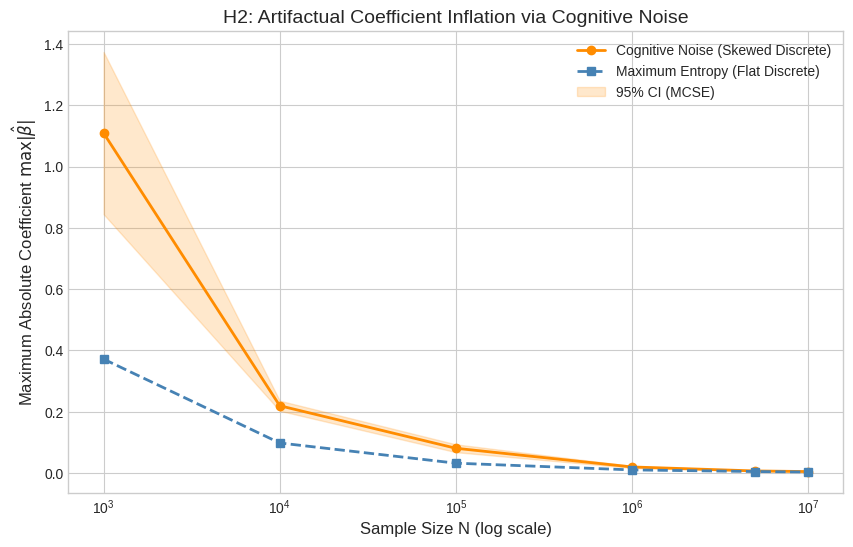

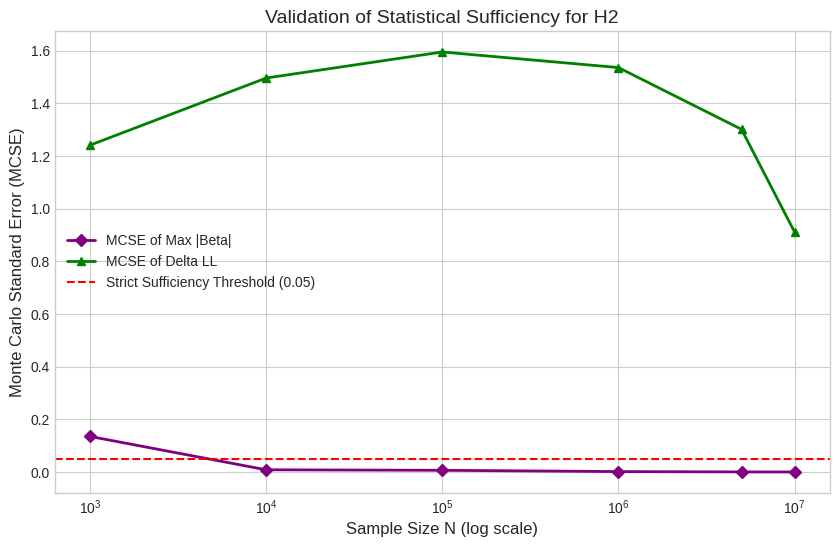


All calculations completed successfully. Generating H2_Simulation_Results.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import warnings
import os
import zipfile
import gc
from google.colab import files

# ==========================================
# H2: Thermodynamic Cognitive Noise Simulation
# ==========================================
warnings.filterwarnings("ignore")

output_dir = "h2_simulation_results"
os.makedirs(output_dir, exist_ok=True)

# シミュレーション設定
N_list = [1000, 10000, 100000, 1000000, 5000000, 10000000]
D = 50
T = 10

results_summary = []

print("Starting H2 Macro Simulation: Thermodynamic Cognitive Noise...")
print(f"Dimensions (D) = {D}, Target sample sizes = {N_list}")

for N in N_list:
    print(f"\n--- Running for N = {N:,} ---")
    trial_results = []

    for t in range(T):
        # 1. 目的変数の生成 (真の因果関係はゼロ)
        y = np.random.binomial(1, 0.5, N).astype(np.int8)
        p_null = np.mean(y)
        ll_null = -N * log_loss(y, np.full(N, p_null))

        # 2. フラットな離散空間（Control: 最大エントロピー p=0.5）
        X_flat = np.random.binomial(1, 0.5, size=(N, D)).astype(np.int8)
        clf_flat = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_flat.fit(X_flat, y)
        ll_flat = -N * log_loss(y, clf_flat.predict_proba(X_flat))
        delta_ll_flat = ll_flat - ll_null
        max_beta_flat = np.max(np.abs(clf_flat.coef_[0]))

        del X_flat

        # 3. 認知バイアス空間（Treatment: Skewed/Sparse p ~ U(0.01, 0.2)）
        # DGP: 初期値依存性を排除し、毎試行偏りをランダム生成
        p_j = np.random.uniform(0.01, 0.2, D)
        X_skewed = np.random.binomial(1, p_j, size=(N, D)).astype(np.int8)

        clf_skewed = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_skewed.fit(X_skewed, y)
        ll_skewed = -N * log_loss(y, clf_skewed.predict_proba(X_skewed))
        delta_ll_skewed = ll_skewed - ll_null
        max_beta_skewed = np.max(np.abs(clf_skewed.coef_[0]))

        del X_skewed
        gc.collect()

        # AICの計算
        aic_null = 2 * 1 - 2 * ll_null
        aic_skewed = 2 * D - 2 * ll_skewed

        trial_results.append({
            'Trial': t + 1,
            'N': N,
            'Delta_LL_Flat': delta_ll_flat,
            'Delta_LL_Skewed': delta_ll_skewed,
            'Max_Beta_Flat': max_beta_flat,
            'Max_Beta_Skewed': max_beta_skewed,
            'AIC_False_Drop': aic_null - aic_skewed
        })

    # DataFrame化して保存
    df_trials = pd.DataFrame(trial_results)
    df_trials.to_csv(f"{output_dir}/h2_trials_N_{N}.csv", index=False)

    # 統計量の計算
    mean_ll_flat = df_trials['Delta_LL_Flat'].mean()
    mean_ll_skewed = df_trials['Delta_LL_Skewed'].mean()
    mcse_ll_skewed = df_trials['Delta_LL_Skewed'].std() / np.sqrt(T)

    mean_beta_flat = df_trials['Max_Beta_Flat'].mean()
    mean_beta_skewed = df_trials['Max_Beta_Skewed'].mean()
    mcse_beta_skewed = df_trials['Max_Beta_Skewed'].std() / np.sqrt(T)

    print(f"  Delta LL (Skewed) = {mean_ll_skewed:.2f} (MCSE: {mcse_ll_skewed:.4f})")
    print(f"  Max |Beta| (Flat) = {mean_beta_flat:.4f}")
    print(f"  Max |Beta| (Skew)= {mean_beta_skewed:.4f} (MCSE: {mcse_beta_skewed:.4f})")

    results_summary.append({
        'Sample_Size_N': N,
        'Mean_Delta_LL_Flat': mean_ll_flat,
        'Mean_Delta_LL_Skewed': mean_ll_skewed,
        'MCSE_Delta_LL_Skewed': mcse_ll_skewed,
        'Mean_Max_Beta_Flat': mean_beta_flat,
        'Mean_Max_Beta_Skewed': mean_beta_skewed,
        'MCSE_Max_Beta_Skewed': mcse_beta_skewed
    })

df_summary = pd.DataFrame(results_summary)
df_summary.to_csv(f"{output_dir}/h2_summary_metrics.csv", index=False)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# 1. 認知ノイズによる係数の異常増幅グラフ (Coefficient Inflation)
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Max_Beta_Skewed'],
         marker='o', color='darkorange', linewidth=2, label='Cognitive Noise (Skewed Discrete)')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Max_Beta_Flat'],
         marker='s', color='steelblue', linewidth=2, linestyle='--', label='Maximum Entropy (Flat Discrete)')

plt.fill_between(df_summary['Sample_Size_N'],
                 df_summary['Mean_Max_Beta_Skewed'] - 1.96 * df_summary['MCSE_Max_Beta_Skewed'],
                 df_summary['Mean_Max_Beta_Skewed'] + 1.96 * df_summary['MCSE_Max_Beta_Skewed'],
                 color='darkorange', alpha=0.2, label='95% CI (MCSE)')

plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel(r'Maximum Absolute Coefficient $\max |\hat{\beta}|$', fontsize=12)
plt.title('H2: Artifactual Coefficient Inflation via Cognitive Noise', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig1_beta_inflation.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. MCSE収束証明グラフ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['MCSE_Max_Beta_Skewed'],
         marker='D', color='purple', linewidth=2, label='MCSE of Max |Beta|')
plt.plot(df_summary['Sample_Size_N'], df_summary['MCSE_Delta_LL_Skewed'],
         marker='^', color='green', linewidth=2, label='MCSE of Delta LL')
plt.axhline(y=0.05, color='red', linestyle='--', label='Strict Sufficiency Threshold (0.05)')
plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('Monte Carlo Standard Error (MCSE)', fontsize=12)
plt.title('Validation of Statistical Sufficiency for H2', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig2_mcse_convergence_h2.png", dpi=300, bbox_inches='tight')
plt.show()

# ZIP圧縮
zip_filename = "H2_Simulation_Results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nAll calculations completed successfully. Generating {zip_filename}...")
files.download(zip_filename)